# Lab 09 — Named Entity Recognition & Information Extraction

Huấn luyện và đánh giá mô hình BERT Token Classification trên tập dữ liệu CoNLL-2003, so sánh với Baseline và ứng dụng vào Information Extraction.

In [1]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset('lhoestq/conll2003')
tag_names = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
print("CoNLL-2003 Dataset Splits:", {k: len(ds[k]) for k in ds})

CoNLL-2003 Dataset Splits: {'train': 14041, 'validation': 3250, 'test': 3453}


## 1. Baseline vs Pretrained Transformer Results

In [2]:
results_df = pd.read_csv('results.csv')
results_df

,Model,Precision,Recall,F1,Architecture
0,Baseline (Logistic Regression),0.6940,0.7408,0.7166,Handcrafted Orthographic Features + SAGA
1,Pretrained Transformer (bert-base-cased),0.9054,0.9196,0.9124,BERT-Encoder + Linear Token Classifier


## 2. Pretrained Transformer (BERT) Learning Curves

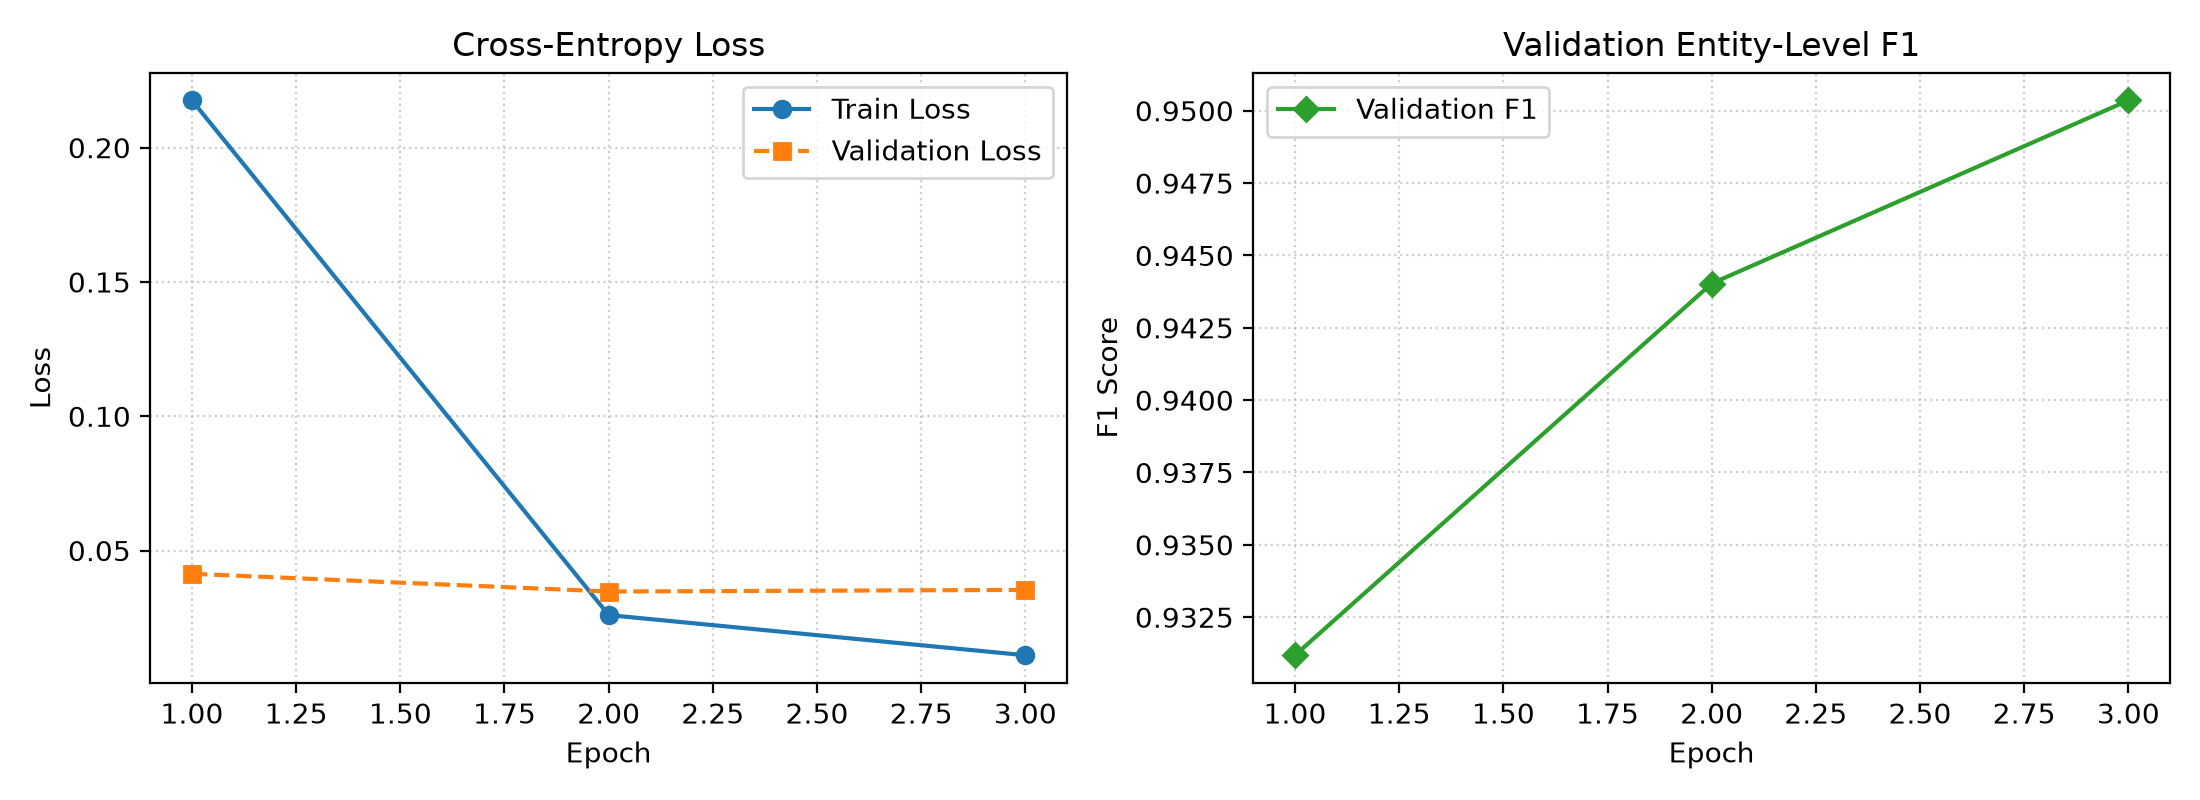

In [3]:
from IPython.display import Image, display

display(Image(filename='learning_curves.png'))

## 3. Entity-Level Evaluation by Type (PER, ORG, LOC, MISC)

In [4]:
entity_df = pd.read_csv('entity_metrics.csv')
entity_df

,Entity,Precision,Recall,F1,Support
0,PER,0.9688,0.9604,0.9646,1615
1,ORG,0.8919,0.9043,0.8981,1661
2,LOC,0.9230,0.9352,0.9290,1666
3,MISC,0.7628,0.8248,0.7926,702


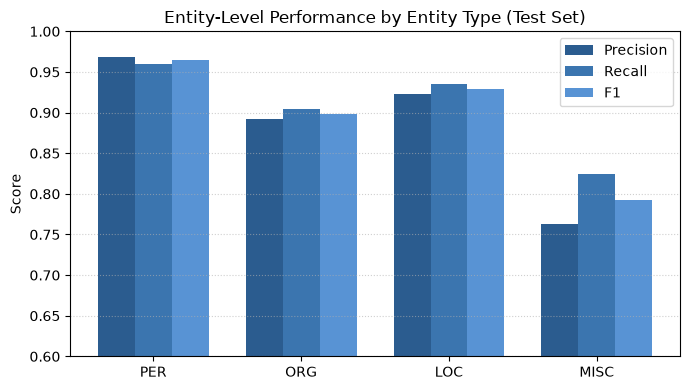

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(entity_df))
width = 0.25

ax.bar([i - width for i in x], entity_df['Precision'], width=width, label='Precision', color='#2b5c8f')
ax.bar([i for i in x], entity_df['Recall'], width=width, label='Recall', color='#3b75af')
ax.bar([i + width for i in x], entity_df['F1'], width=width, label='F1', color='#5893d4')

ax.set_xticks(x)
ax.set_xticklabels(entity_df['Entity'])
ax.set_ylabel('Score')
ax.set_ylim(0.6, 1.0)
ax.set_title('Entity-Level Performance by Entity Type (Test Set)')
ax.legend()
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Entity Length Analysis (Experiment 5)

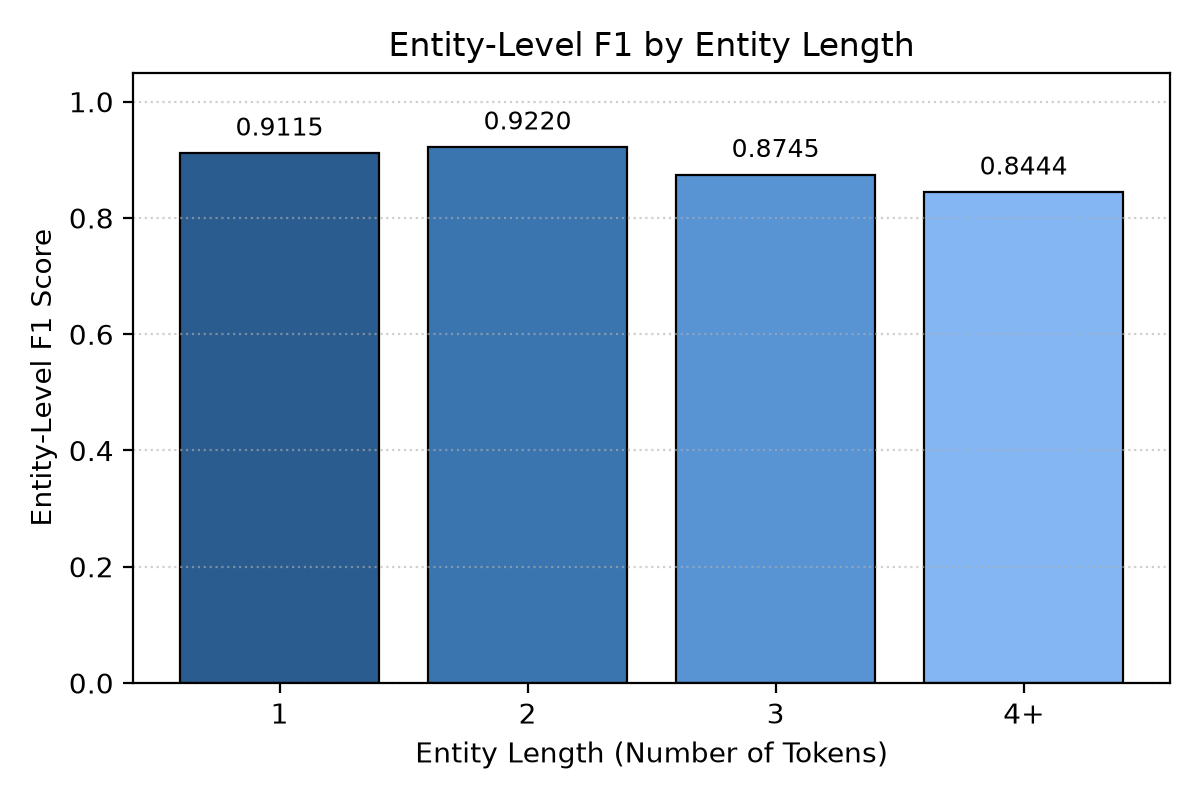

In [6]:
display(Image(filename='entity_length_analysis.png'))

## 5. Token-Level Confusion Matrix

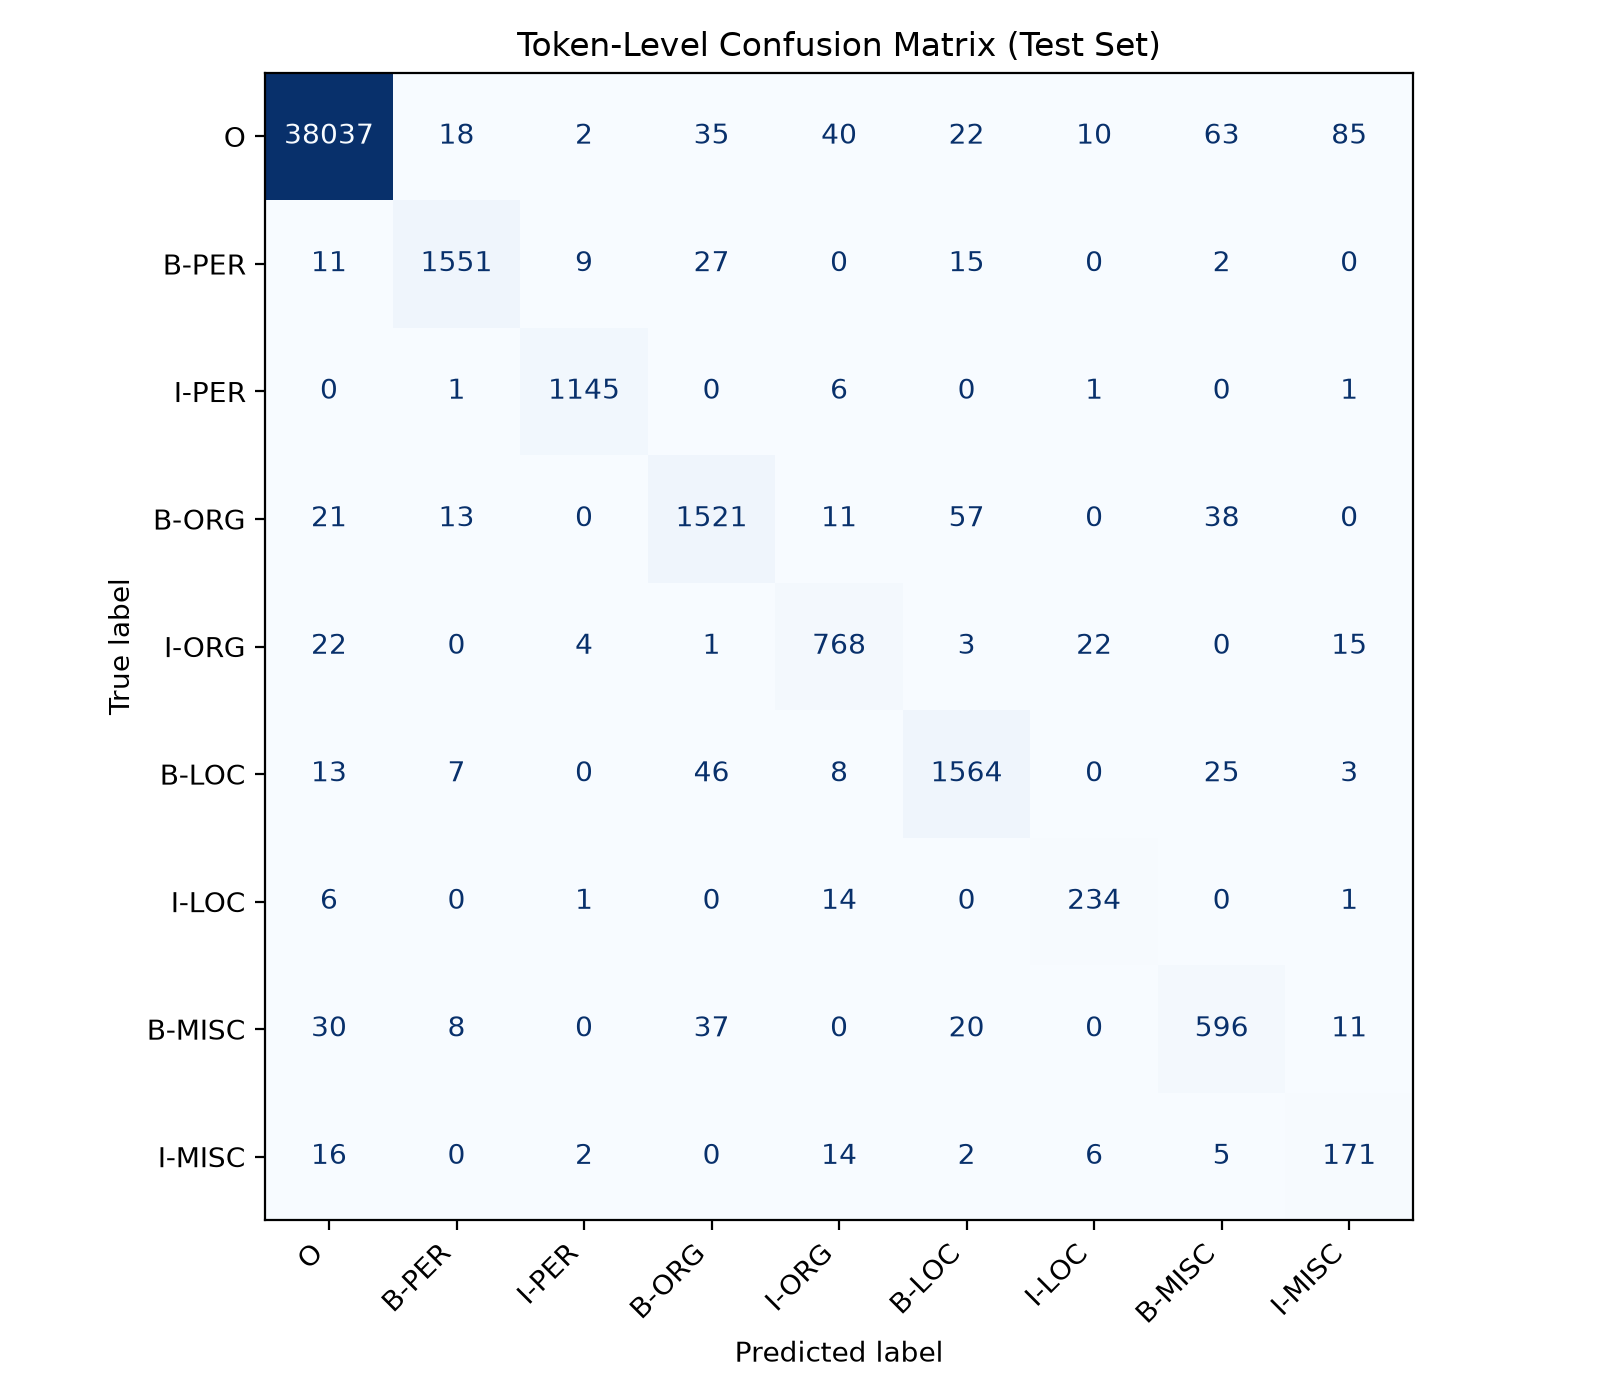

In [7]:
display(Image(filename='confusion_matrix.png'))

## 6. Qualitative Error Analysis (Experiment 6)

In [8]:
import json

with open('error_samples.json') as f:
    errors = json.load(f)

for category in ['false_positives', 'false_negatives', 'boundary_errors']:
    print(f"\n=== {category.upper().replace('_', ' ')} (Top 3) ===")
    for item in errors[category][:3]:
        print(f"Context: {item['text']}")
        print(f"  Gold: {item['gold']}  |  Pred: {item['pred']}")


=== FALSE POSITIVES (Top 3) ===
Context: JAPAN GET LUCKY WIN ,
  Gold: O  |  Pred: LOC: LUCKY
Context: a Group C championship match
  Gold: O  |  Pred: MISC: C
Context: GOLF - ZIMBABWE
  Gold: O  |  Pred: LOC: GOLF

=== FALSE NEGATIVES (Top 3) ===
Context: BACK FOR ITALY AFTER A
  Gold: LOC: ITALY  |  Pred: O
Context: TO MISS CAMPESE FAREWELL .
  Gold: PER: CAMPESE  |  Pred: O
Context: AUSTRALIA V WEST INDIES WORLD SERIES
  Gold: LOC: WEST INDIES  |  Pred: O

=== BOUNDARY ERRORS (Top 3) ===
Context: SOCCER - JAPAN GET LUCKY
  Gold: LOC: JAPAN  |  Pred: PER: JAPAN
Context: WIN , CHINA IN SURPRISE
  Gold: PER: CHINA  |  Pred: ORG: CHINA
Context: corner of Bitar 's goal
  Gold: PER: Bitar  |  Pred: ORG: Bitar


## 7. Context Analysis: Ambiguous Surface Forms

In [9]:
with open('context_analysis.json') as f:
    ambiguous = json.load(f)

for surface, occurrences in list(ambiguous.items())[:3]:
    print(f"\nSurface Form: '{surface}'")
    for occ in occurrences[:2]:
        print(f"  [{occ['type']}] {occ['context']}")


Surface Form: 'Barcelona'
  [LOC] FIFA 's players ' status committee , meeting in Barcelona , decided that although the Udinese document was basically valid , it could not be legally protected .
  [ORG] Barcelona ( Spain ) 9 4 5 13

Surface Form: 'Charleroi'
  [ORG] Charleroi ( Belgium ) 9 0 9 9
  [LOC] In Charleroi :

Surface Form: 'Pontypridd'
  [LOC] Barbarians - 15 - Tim Stimpson ( England ) ; 14 - Nigel Walker ( Wales ) , 13 - Allan Bateman ( Wales ) , 12 - Gregor Townsend ( Scotland ) , 11 - Tony Underwood ( England ) ; 10 - Rob Andrew ( England ) , 9 - Rob Howley ( Wales ) ; 8 - Scott Quinnell ( Wales ) , 7 - Neil Back ( England ) , 6 - Dale McIntosh ( Pontypridd ) , 5 - Ian Jones ( New Zealand ) , 4 - Craig Quinnell ( Wales ) , 3 - Darren Garforth ( Leicester ) , 2 - Norm Hewitt ( New Zealand ) , 1 - Nick Popplewell ( Ireland ) .
  [ORG] Pontypridd 53 Bridgend 9


## 8. Application: Information Extraction Pipeline

In [10]:
from information_extraction import InformationExtractor

ie = InformationExtractor()

sample_texts = [
    "Barack Obama visited Paris yesterday.",
    "Microsoft and Google signed a partnership in New York.",
    "The United Nations held an emergency summit in Geneva on Friday."
]

for text in sample_texts:
    res = ie.extract_entities(text)
    print(f"\nText:   '{text}'")
    print(f"Output: {res}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Text:   'Barack Obama visited Paris yesterday.'
Output: {'PERSON': ['Barack Obama'], 'LOCATION': ['Paris']}

Text:   'Microsoft and Google signed a partnership in New York.'
Output: {'ORGANIZATION': ['Microsoft', 'Google'], 'LOCATION': ['New York']}

Text:   'The United Nations held an emergency summit in Geneva on Friday.'
Output: {'ORGANIZATION': ['United Nations'], 'LOCATION': ['Geneva']}
